# Step 2 · Competitive landscape of flying drones (Client: Leonardo S.p.A.)

**Team 28 · Innovation Management (01TXIWS) · A.Y. 2026/27**

This notebook answers the Step 2 questions of the PW, following Tutorial 11 (Section 5), on the same DOCDB family universe as Step 1 and with the Team 28 name harmoniser (`src/harmonize.py`, benchmarked in `03_step2_harmonization_benchmark.ipynb`).

| Question (deck, Step 2) | Section |
|---|---|
| How concentrated is the field, and is it consolidating? | 4 |
| Who are the incumbents, and who are the new entrants? | 5 |
| Which subfields are growing fastest? | 6 |
| Which forces shape the field (PEST)? | `docs/LEONARDO_CLIENT_AND_PEST_ANALYSIS.md` |

## 1. Setup

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("/home/jovyan/Patent-study")

if not REPO_ROOT.exists():
    raise FileNotFoundError(f"Project not found: {REPO_ROOT}")

sys.path.insert(0, str(REPO_ROOT)) if str(REPO_ROOT) not in sys.path else None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config_loader import load_config, get_last_complete_year
from src.harmonize import harmonize_applicant_names, six_concentration_measures

cfg = load_config(REPO_ROOT / "config" / "sector.yaml")

print("Repo root:", REPO_ROOT)
print("Sector:", cfg["project"]["sector_name"])
print("Client:", cfg["project"]["client_name"])

Repo root: /home/jovyan/Patent-study
Sector: Flying drones
Client: Leonardo S.p.A.


In [2]:
# ---------------------------------------------------------------- run settings
ENV = "PROD"            # develop on TEST, switch to "PROD" for the final numbers
USE_CACHE = True        # reuse the PATSTAT extraction saved by a previous run
CACHE = (
    REPO_ROOT
    / "data"
    / "processed"
    / f"step2_extract_{ENV}_step0csv.pkl"
)

CACHE.parent.mkdir(parents=True, exist_ok=True)
# ---------------------------------------------------------------- analysis parameters
SECTOR_NAME = cfg["project"]["sector_name"]
CLIENT = "LEONARDO"                                    # harmonised name of the client
YEAR_MIN = int(cfg["time_window"]["year_min"])         # 2004
YEAR_MAX = int(cfg["time_window"]["year_max"])         # 2025
LAST_COMPLETE_YEAR = get_last_complete_year(cfg)       # 2022: the last 3 years are incomplete
IPR_TYPE = cfg["counting_rules"]["ipr_type"]           # "PI": patents of invention only
SPLIT_YEAR = int(cfg["counting_rules"]["incumbent_split_year"])   # 2018: incumbents file before
TOP_N = int(cfg["counting_rules"]["top_n_applicants"]) # 15 rows in the top-applicants table
WINDOW = 3                                             # years per window for concentration over time

# ---------------------------------------------------------------- where the results go
OUT = REPO_ROOT / "outputs" / "step2_competitive_landscape"
OUT.mkdir(parents=True, exist_ok=True)

print(f"{SECTOR_NAME} | ENV={ENV}")
print(f"Families: {YEAR_MIN}-{YEAR_MAX}, complete up to {LAST_COMPLETE_YEAR}")
print(f"Incumbents: first family before {SPLIT_YEAR}")
print(f"Top applicants: {TOP_N} | Window: {WINDOW} years")

Flying drones | ENV=PROD
Families: 2004-2025, complete up to 2022
Incumbents: first family before 2018
Top applicants: 15 | Window: 3 years


In [3]:
RAW_DIR = REPO_ROOT / "data" / "raw"

print("Raw directory:", RAW_DIR)
print("Directory exists:", RAW_DIR.exists())

if RAW_DIR.exists():
    for f in RAW_DIR.iterdir():
        print(f.name)

Raw directory: /home/jovyan/Patent-study/data/raw
Directory exists: True
00_family_roster.csv


## 2. Data: the sector's families, their applicants and their CPC codes

The family universe is the one of Step 0/Step 1: Samuele's `uav_final_query_families.csv` if it is in `data/uav_core_boundary_validation/`, otherwise the fallback query built from `config/sector.yaml` (core CPC/IPC codes + boundary subgroups gated by UAV keywords).

In [4]:
# ----------------------------------------------------------------
# Load Step 0 family roster
# ----------------------------------------------------------------

STEP0_CSV_PATH = RAW_DIR / "00_family_roster.csv"

step0_df = pd.read_csv(STEP0_CSV_PATH)

fids = (
    step0_df["docdb_family_id"]
    .dropna()
    .astype("int64")
    .drop_duplicates()
    .tolist()
)

print(f"Loaded {len(fids):,} DOCDB families")
print(step0_df["stratum"].value_counts())

step0_df.head()

Loaded 71,197 DOCDB families
stratum
core               61967
boundary_rescue     9230
Name: count, dtype: int64


,docdb_family_id,stratum
0,72646400,core
1,95696073,core
2,41259472,core
3,88043338,core
4,52365167,core


In [5]:
from epo.tipdata.patstat import PatstatClient

# PATSTAT connection
patstat = PatstatClient(env=ENV)
db = patstat.orm()

# Batch iterator
def iter_batches(items, batch_size=5000):
    for start in range(0, len(items), batch_size):
        yield items[start:start + batch_size]

print(f"Connected to PATSTAT ({ENV})")

Connected to PATSTAT (PROD)


For every family we query, in batches of 5,000 families:

- **year** = the earliest filing (priority) year among its applications, as in Step 1;
- **applicants** = persons with `applt_seq_nr > 0` (owners, not inventors), with PATSTAT standardised name (`psn_name`), sector and country;
- **CPC codes**, for the subfields of Section 6.

In [6]:
from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS206_PERSON, TLS207_PERS_APPLN, TLS224_APPLN_CPC
from sqlalchemy import func


def fetch_family_data(family_ids):
    "Year, applicants and CPC codes of the given DOCDB families (queried in batches of 5,000)."
    years, applicants, cpcs = [], [], []
    for batch in iter_batches(family_ids, batch_size=5000):
        # 1. family year = earliest filing year among its applications
        years.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"),
                     func.min(TLS201_APPLN.earliest_filing_year).label("year"))
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE)
            .group_by(TLS201_APPLN.docdb_family_id)
        ))
        # 2. applicants of every family (one row per family and person)
        applicants.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), TLS206_PERSON.psn_id,
                     TLS206_PERSON.psn_name, TLS206_PERSON.psn_sector,
                     func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
            .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
            .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE,
                    TLS207_PERS_APPLN.applt_seq_nr > 0)
            .distinct()
        ))
        # 3. CPC codes of every family (blanks removed: "B64U 10/13" -> "B64U10/13")
        cpcs.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"),
                     func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
            .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE)
            .distinct()
        ))
    return {
        "family_year": pd.concat(years, ignore_index=True),
        "raw": pd.concat(applicants, ignore_index=True),
        "family_cpc": pd.concat(cpcs, ignore_index=True),
    }


# quick test on the first 50 families
test = fetch_family_data(fids[:50])
for key, df in test.items():
    print(f"{key}: {len(df):,} rows")
test["raw"].head()

family_year: 50 rows
raw: 99 rows
family_cpc: 557 rows


,unit_id,psn_id,psn_name,psn_sector,ctry
0,71076397,26564980,RAKUTEN,COMPANY,JP
1,65634255,31716938,SZ DJI TECHNOLOGY COMPANY,COMPANY,US
2,84766959,183279196,"Rakuten Group, Inc.",UNKNOWN,JP
3,61687595,21403583,MCAFEE,COMPANY,US
4,41259472,6340674,DCNS,COMPANY,FR


We also query the **first patent ever** (in any field) of each applicant, to tell newcomers to patenting from established patentees that enter drones. The whole extraction is saved in `data/processed/` and reused on the next runs (`USE_CACHE = True`).

In [7]:
def fetch_first_patents(psn_ids):
    "First filing year of each PATSTAT standardised applicant, in any technology."
    parts = []
    for batch in iter_batches(psn_ids, batch_size=5000):
        parts.append(patstat.df(
            db.query(
                TLS206_PERSON.psn_id,
                func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year")
            )
            .join(
                TLS207_PERS_APPLN,
                TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id
            )
            .join(
                TLS201_APPLN,
                TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id
            )
            .filter(
                TLS206_PERSON.psn_id.in_(batch),
                TLS207_PERS_APPLN.applt_seq_nr > 0,
                TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX)
            )
            .group_by(TLS206_PERSON.psn_id)
        ))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()



# Load cache or extract data
if USE_CACHE and CACHE.exists():
    data = pd.read_pickle(CACHE)
    print(f"Loaded cached extraction: {CACHE.name}")
else:
    print("Extracting family data from PATSTAT...")
    data = fetch_family_data(fids)
    psn_ids = [
        int(i)
        for i in data["raw"]["psn_id"].dropna().unique()
    ]
    print(f"Found {len(psn_ids):,} unique applicants")
    data["first_patents"] = fetch_first_patents(psn_ids)
    pd.to_pickle(data, CACHE)
    print(f"Saved extraction: {CACHE}")

# Extraction summary
for key in ("family_year", "raw", "family_cpc", "first_patents"):
    print(f"{key:>14}: {len(data[key]):,} rows")

Extracting family data from PATSTAT...
Found 36,462 unique applicants
Saved extraction: /home/jovyan/Patent-study/data/processed/step2_extract_PROD_step0csv.pkl
   family_year: 71,197 rows
           raw: 99,420 rows
    family_cpc: 460,829 rows
 first_patents: 36,462 rows


## 3. Applicants: harmonised names, type and country

- **Names**: `src/harmonize.py` with the corporate trees of `config/sector.yaml` (e.g. Finmeccanica, Selex, OTO Melara, AgustaWestland → LEONARDO; Google, X, Wing, Makani → ALPHABET). The Chinese name of X Development loses its characters in the ASCII normalisation, so it is mapped by hand.
- **Individuals are never merged**: they are people, and merging them by surname creates fake applicants (*LEE*, *WANG*). They keep their PATSTAT name.
- Only families with a year between `YEAR_MIN` and `YEAR_MAX` are kept.

In [8]:
# families inside the time window, and their applicants
family_year = data["family_year"].dropna()
family_year = family_year[family_year["year"].between(YEAR_MIN, YEAR_MAX)]
raw = data["raw"].dropna(subset=["psn_name"]).merge(family_year, on="unit_id")

# 1. harmonised names, with the corporate trees of config/sector.yaml
hmap = harmonize_applicant_names(raw["psn_name"].unique(),
                                 domain_groups=cfg["domain_corporate_groups"],
                                 apply_domain_aliases=True)
hmap.update({n: "ALPHABET" for n in hmap if "X开发" in str(n)})   # Chinese name of X Development
raw["applicant"] = raw["psn_name"].map(hmap)

# 2. individuals keep their own PATSTAT name
is_person = raw["psn_sector"].astype(str).str.upper().str.contains("INDIVIDUAL")
raw.loc[is_person, "applicant"] = raw.loc[is_person, "psn_name"]

print(f"{raw['unit_id'].nunique():,} families in {YEAR_MIN}-{YEAR_MAX}")
print(f"{raw['psn_name'].nunique():,} PATSTAT names -> {raw['applicant'].nunique():,} harmonised applicants")
print(f"{is_person.sum():,} rows are individuals (kept with their own name)")

70,845 families in 2004-2025
35,165 PATSTAT names -> 27,226 harmonised applicants
11,593 rows are individuals (kept with their own name)


For each harmonised applicant: its **type** (firm, university, …, from `psn_sector`), its **country** (the most frequent known one, as in Tutorial 11) and its **first patent ever** (the earliest among the PATSTAT names it groups). Two versions of the family–applicant links are kept: **harmonised** names and **raw** PATSTAT names, to show how much harmonisation changes the measures.

In [9]:
def applicant_type(psn_sector):
    "Translate the PATSTAT psn_sector into the types used in the deck (Tutorial 11)."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"


# 1. type and main country of each harmonised applicant
raw["type"] = raw["psn_sector"].map(applicant_type)
raw["ctry"] = raw["ctry"].replace("", np.nan)
main_type = raw.groupby("applicant")["type"].agg(lambda t: t.value_counts().index[0])
main_country = (raw.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
                .groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0]))

# 2. one row per (family, applicant): harmonised names and raw PATSTAT names
links = raw[["unit_id", "year", "applicant"]].drop_duplicates()
links_raw = raw[["unit_id", "year", "psn_name"]].drop_duplicates().rename(columns={"psn_name": "applicant"})

# 3. first patent ever of each harmonised applicant = the earliest among its PATSTAT names
first_ever = (raw[["psn_id", "applicant"]].drop_duplicates()
              .merge(data["first_patents"], on="psn_id")
              .groupby("applicant")["first_patent_year"].min())

print(f"links: {len(links):,} family-applicant pairs (harmonised) | links_raw: {len(links_raw):,} (raw)")
print(main_type.value_counts().to_string())

links: 85,118 family-applicant pairs (harmonised) | links_raw: 91,896 (raw)
type
unknown                    8618
firm                       8418
individual                 8067
university                 1510
government / non-profit     596
hospital                     17


## 4. Question: how concentrated is the field, and is it consolidating?

First the six measures of Liston-Heyes & Pilkington (2004) on the whole period (complete years only), with **families** in place of patents, **before and after** name harmonisation. Then, in 4b, HH, its numbers-equivalent 1/HH and CR4 on windows of `WINDOW` years: the field is **consolidating** if HH and CR4 rise and 1/HH falls over time.

In [10]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
complete_raw = links_raw[links_raw["year"] <= LAST_COMPLETE_YEAR]

families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()
families_per_name = complete_raw.groupby("applicant")["unit_id"].nunique()

conc = pd.DataFrame({
    "PATSTAT names (raw)": six_concentration_measures(families_per_name.to_numpy()),
    "Harmonised (Team 28)": six_concentration_measures(families_per_applicant.to_numpy()),
})
conc.to_csv(OUT / "concentration_raw_vs_harmonized.csv")
print(f"{SECTOR_NAME}, families {YEAR_MIN}-{LAST_COMPLETE_YEAR}")
conc.round(4)

Flying drones, families 2004-2022


,PATSTAT names (raw),Harmonised (Team 28)
n_applicants,26631.0000,21355.0000
CR4_pct,4.0327,5.3829
CR8_pct,5.9316,7.5377
HH,0.0011,0.0015
numbers_equivalent_1_over_HH,925.4325,647.9017
CV,5.2705,5.6535
Gini,0.5545,0.5973
Lotka_L,-1.5030,-1.4011
Lotka_p_value,0.0000,0.0000


### 4.1 Concentration over time

Windows of `WINDOW` consecutive years, aligned on the last complete year (e.g. 2020-2022, 2017-2019, …), for harmonised and raw names.

In [11]:
def windows(last, first, size):
    "Consecutive windows of `size` years ending on `last`, all starting on or after `first`."
    ends = range(last, first + size - 2, -size)
    return sorted((end - size + 1, end) for end in ends)


KEEP = ["n_applicants", "CR4_pct", "CR8_pct", "HH", "numbers_equivalent_1_over_HH"]
rows = []
for start, end in windows(LAST_COMPLETE_YEAR, YEAR_MIN, WINDOW):
    for names, df in (("harmonised", links), ("raw", links_raw)):
        w = df[df["year"].between(start, end)]
        if w.empty:
            continue
        m = six_concentration_measures(w.groupby("applicant")["unit_id"].nunique().to_numpy())
        rows.append({"window": f"{start}-{end}", "start": start, "names": names,
                     "families": w["unit_id"].nunique(), **{k: m[k] for k in KEEP}})
trend = pd.DataFrame(rows)
trend.to_csv(OUT / "concentration_trend_windows.csv", index=False)

trend[trend["names"] == "harmonised"].drop(columns=["start", "names"]).set_index("window").round(4)

,families,n_applicants,CR4_pct,CR8_pct,HH,numbers_equivalent_1_over_HH
window,,,,,,
2005-2007,391,676,9.7162,13.7555,0.0043,234.7666
2008-2010,675,1231,6.9899,9.5829,0.0027,369.0286
2011-2013,1180,1305,8.7961,12.4816,0.0036,279.7558
2014-2016,8942,4713,7.9749,10.7409,0.0033,299.6441
2017-2019,19062,8227,6.6541,9.0066,0.0025,400.5527
2020-2022,20239,9245,5.0405,7.6930,0.0015,689.3216


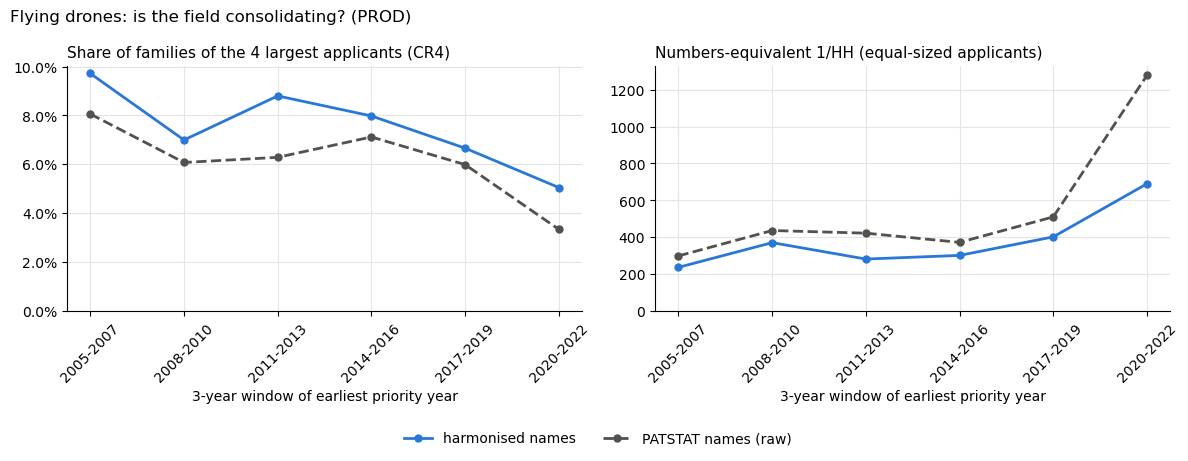

In [12]:
from matplotlib.ticker import PercentFormatter

C_MAIN, C_MUTED, C_GRID = "#2a78d6", "#52514e", "#e6e5e1"   # blue for harmonised, grey for raw
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C_GRID, "axes.axisbelow": True, "legend.frameon": False})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
panels = [(axes[0], "CR4_pct", "Share of families of the 4 largest applicants (CR4)"),
          (axes[1], "numbers_equivalent_1_over_HH", "Numbers-equivalent 1/HH (equal-sized applicants)")]
series = [("harmonised", "harmonised names", C_MAIN, "-"), ("raw", "PATSTAT names (raw)", C_MUTED, "--")]

for ax, col, title in panels:
    for names, label, color, style in series:
        t = trend[trend["names"] == names].sort_values("start")
        ax.plot(t["window"], t[col], linestyle=style, color=color, marker="o", markersize=5, lw=2, label=label)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(f"{WINDOW}-year window of earliest priority year")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(bottom=0)
axes[0].yaxis.set_major_formatter(PercentFormatter(100))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"{SECTOR_NAME}: is the field consolidating? ({ENV})", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(OUT / "fig_step2_concentration_trend.png", dpi=200, bbox_inches="tight")

plt.show()

In [13]:
#non mandatory, we can delete but it creates the answer 

MIN_FAMILIES_WINDOW = 50   # windows with fewer families are too small to compare

h = (trend[(trend["names"] == "harmonised") & (trend["families"] >= MIN_FAMILIES_WINDOW)]
     .sort_values("start").set_index("window"))
whole = conc["Harmonised (Team 28)"]
first, last = h.iloc[0], h.iloc[-1]
peak = h["CR4_pct"].idxmax()

signals = sum([last["HH"] > first["HH"],
               last["CR4_pct"] > first["CR4_pct"],
               last["numbers_equivalent_1_over_HH"] < first["numbers_equivalent_1_over_HH"]])
verdict = {3: "more concentrated (consolidating)", 0: "less concentrated (more and more players)"}.get(signals, "mixed signals")

print("Q: How concentrated is the field, and is it consolidating?")
print(f"A: Over {YEAR_MIN}-{LAST_COMPLETE_YEAR} the 4 largest applicants hold {whole['CR4_pct']:.1f}% of the families "
      f"(HH = {whole['HH']:.4f}, like {whole['numbers_equivalent_1_over_HH']:.0f} equal-sized applicants): a fragmented field.")
print(f"   From {h.index[0]} to {h.index[-1]}: CR4 {first['CR4_pct']:.1f}% -> {last['CR4_pct']:.1f}%, "
      f"1/HH {first['numbers_equivalent_1_over_HH']:.0f} -> {last['numbers_equivalent_1_over_HH']:.0f}, "
      f"applicants {first['n_applicants']:.0f} -> {last['n_applicants']:.0f}: {verdict}.")
print(f"   CR4 peaked in {peak} ({h.loc[peak, 'CR4_pct']:.1f}%). "
      f"Windows with fewer than {MIN_FAMILIES_WINDOW} families are left out of the comparison.")

Q: How concentrated is the field, and is it consolidating?
A: Over 2004-2022 the 4 largest applicants hold 5.4% of the families (HH = 0.0015, like 648 equal-sized applicants): a fragmented field.
   From 2005-2007 to 2020-2022: CR4 9.7% -> 5.0%, 1/HH 235 -> 689, applicants 676 -> 9245: less concentrated (more and more players).
   CR4 peaked in 2005-2007 (9.7%). Windows with fewer than 50 families are left out of the comparison.


## 5. Question: who are the incumbents, and who are the new entrants?

**Top applicants**: type, country, families, families since `SPLIT_YEAR`, first and last year in the sector, first patent ever (any field), and status:

- **incumbent**: first family in the sector before `SPLIT_YEAR`;
- **entrant**: first family in the sector from `SPLIT_YEAR` on.

The client is added at the bottom of the table if it is not among the top `TOP_N`.

In [14]:
by_app = links.groupby("applicant")
since = f"families since {SPLIT_YEAR}"

top = pd.DataFrame({
    "type": main_type,
    "country": main_country,
    "families": by_app["unit_id"].nunique(),
    since: links[links["year"] >= SPLIT_YEAR].groupby("applicant")["unit_id"].nunique(),
    "first year in the sector": by_app["year"].min(),
    "last year in the sector": by_app["year"].max(),
    "first patent ever": first_ever,
}).dropna(subset=["families"])
top[since] = top[since].fillna(0).astype(int)
top["status"] = np.where(top["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")
top = top.sort_values("families", ascending=False)
top.insert(0, "rank", top["families"].rank(ascending=False, method="min").astype(int))   # ties share the best rank
top.index.name = "applicant"
top.to_csv(OUT / "top_applicants.csv")

shown = top.head(TOP_N)
if CLIENT in top.index and CLIENT not in shown.index:
    shown = pd.concat([shown, top.loc[[CLIENT]]])
shown

,rank,type,country,families,families since 2018,first year in the sector,last year in the sector,first patent ever,status
applicant,,,,,,,,,
DJI,1,firm,CN,1643,755,2011,2025,2003,incumbent
STATE GRID CORP OF CHINA,2,firm,CN,1618,1527,2012,2025,2003,incumbent
BOEING,3,firm,US,606,301,2004,2025,1918,incumbent
BEIHANG UNIVERSITY,4,university,CN,538,467,2006,2025,1985,incumbent
NANJING UNIV AERONAUTICS ASTRONAUTICS,5,university,CN,529,473,2009,2025,1987,incumbent
AUTEL ROBOTICS,6,firm,CN,454,298,2013,2025,2013,incumbent
NORTHWESTERN POLYTECHNICAL UNIVERSITY,7,university,CN,417,374,2014,2025,1986,incumbent
POWER GRID,8,firm,CN,404,396,2016,2025,1998,incumbent
AMAZON,9,firm,US,387,121,2013,2025,1997,incumbent


**Entry and exit, year by year** (Tutorial 11):

- **active applicants**: applicants with at least one family in year *t*;
- **new to the sector**: active applicants whose first family in the sector is in *t*;
- **new to patenting**: active applicants whose first patent ever, in any field, is in *t*;
- **entrants' share of families**: share of the families of *t* with at least one applicant new to the sector;
- **rate of disappearance**: share of the applicants active in *t* that never file again in the sector, shown only up to 3 years before the last complete year.

In the first years almost every applicant looks "new" because we do not see families before `YEAR_MIN`: read entry from a few years after `YEAR_MIN`.

In [15]:
first_year = by_app["year"].min()   # first family of each applicant in the sector
last_year = by_app["year"].max()    # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = (
    links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
)
entry_exit.to_csv(OUT / "entry_exit_by_year.csv")
entry_exit.round(1)

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2004,173,173,78,114,65.9,100.0
2005,174,160,82,112,64.4,77.0
2006,324,277,148,244,75.3,86.2
2007,237,209,123,184,77.6,84.1
2008,402,354,219,286,71.1,84.8
2009,503,427,216,366,72.8,83.2
2010,461,359,181,326,70.7,76.0
2011,499,409,222,374,74.9,79.3
2012,475,375,165,309,65.1,65.3


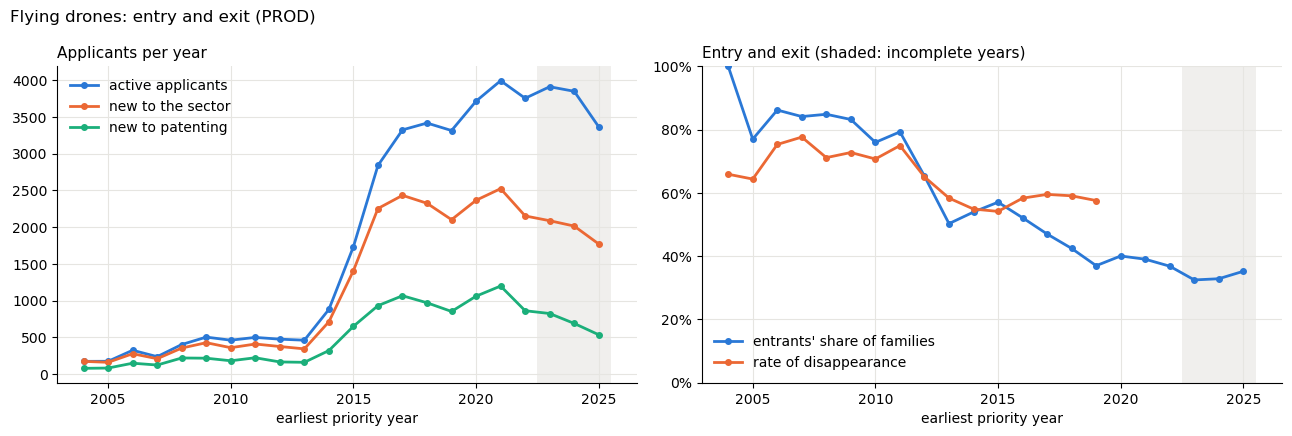

In [16]:
C_ACCENT, C_THIRD = "#eb6834", "#1baf7a"   # orange and green: categorical slots 2 and 3

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
left = [("active_applicants", "active applicants", C_MAIN),
        ("new_to_the_sector", "new to the sector", C_ACCENT),
        ("new_to_patenting", "new to patenting", C_THIRD)]
right = [("entrants' share of families (%)", "entrants' share of families", C_MAIN),
         ("rate of disappearance (%)", "rate of disappearance", C_ACCENT)]

for ax, specs in ((axes[0], left), (axes[1], right)):
    for col, label, color in specs:
        s = entry_exit[col].dropna()
        ax.plot(s.index, s.values, color=color, marker="o", markersize=4, lw=2, label=label)
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color=C_GRID, alpha=0.6, lw=0)   # incomplete years
    ax.set_xlabel("earliest priority year")
axes[0].set_title("Applicants per year", loc="left", fontsize=11)
axes[0].legend(loc="upper left")
axes[1].set_title("Entry and exit (shaded: incomplete years)", loc="left", fontsize=11)
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
axes[1].legend(loc="lower left")
fig.suptitle(f"{SECTOR_NAME}: entry and exit ({ENV})", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "fig_step2_entry_exit.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Question: which subfields are growing fastest?

A **subfield** is a CPC group inside the UAV-specific areas (B64U, G05D 1, G08G 5), cut at the first two digits after the slash, as in Tutorial 11 (e.g. `B64U2101/30` → `B64U2101/30`, `G05D1/101` → `G05D1/10`). We count the families of each subfield in the last 5 complete years and in the 5 years before.

Two cautions: the `area` column only gives the B64U **main group**, so check the exact title of each subgroup in the CPC scheme (cooperativepatentclassification.org); and G05D 1 was reorganised in 2024, so a very fast growth of a new G05D 1 subgroup can partly be a reclassification effect.

In [17]:
from src.config_loader import get_b64u_group_definition

SUBFIELD_PREFIXES = ("B64U", "G05D1/", "G08G5/")
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)   # the last 5 complete years: 2018-2022
PAST = (RECENT[0] - 5, RECENT[0] - 1)                   # the 5 years before: 2013-2017
OTHER_AREAS = {"G05D1": "Control of position, course or attitude of vehicles (autonomy)",
               "G08G5": "Traffic control systems for aircraft (UTM, geofencing)"}


def subfield(cpc):
    "CPC group with the first two digits after the slash: G05D1/101 -> G05D1/10."
    main_group, _, subgroup = str(cpc).partition("/")
    return f"{main_group}/{subgroup[:2]}"


def area(sub):
    "Readable name of the main group of a subfield."
    main_group = sub.split("/")[0]
    if main_group.startswith("B64U"):
        return get_b64u_group_definition(main_group + "/", cfg)
    return OTHER_AREAS.get(main_group, "")


# CPC codes of the sector's families, restricted to the UAV-specific areas
fc = data["family_cpc"].merge(family_year, on="unit_id")
in_scope = fc[fc["cpc"].astype(str).str.startswith(SUBFIELD_PREFIXES)].copy()
in_scope["subfield"] = in_scope["cpc"].map(subfield)
in_scope = in_scope.drop_duplicates(["unit_id", "subfield"])   # a family counts once per subfield

# families per subfield in the two periods, and growth
past = in_scope[in_scope["year"].between(*PAST)].groupby("subfield")["unit_id"].nunique()
recent = in_scope[in_scope["year"].between(*RECENT)].groupby("subfield")["unit_id"].nunique()
past_col, recent_col = f"families {PAST[0]}-{PAST[1]}", f"families {RECENT[0]}-{RECENT[1]}"

subfields = pd.DataFrame({past_col: past, recent_col: recent}).fillna(0).astype(int)
subfields["growth (%)"] = (subfields[recent_col] / subfields[past_col].where(subfields[past_col] > 0) - 1) * 100
subfields["area"] = subfields.index.map(area)
subfields = subfields.sort_values(recent_col, ascending=False)
subfields.index.name = "subfield"
subfields.to_csv(OUT / "subfield_growth.csv")
subfields.head(20).round(1)

,families 2013-2017,families 2018-2022,growth (%),area
subfield,,,,
G05D1/10,2922,7748,165.2,"Control of position, course or attitude of veh..."
B64U2101/30,3349,4221,26.0,Indexing scheme: UAVs characterised by intende...
B64U2101/00,1416,4155,193.4,Indexing scheme: UAVs characterised by intende...
B64U10/10,1861,3792,103.8,"Type of UAV (rotorcrafts, multirotors, VTOL, f..."
B64U50/19,2102,3598,71.2,"Propulsion; power supply (motors, batteries, f..."
B64U2201/20,3006,3181,5.8,"Indexing scheme: UAV control, navigation and c..."
B64U2201/10,2366,2792,18.0,"Indexing scheme: UAV control, navigation and c..."
B64U10/13,1607,2222,38.3,"Type of UAV (rotorcrafts, multirotors, VTOL, f..."
G05D1/00,2261,1994,-11.8,"Control of position, course or attitude of veh..."


In [18]:
# families of the whole sector in the two periods
n_past = family_year["year"].between(*PAST).sum()
n_recent = family_year["year"].between(*RECENT).sum()
sector_growth = (n_recent / n_past - 1) * 100
print(f"Whole sector: {n_past:,} families in {PAST[0]}-{PAST[1]} -> {n_recent:,} in {RECENT[0]}-{RECENT[1]} "
      f"({sector_growth:+.1f}%)")

# share of the sector's families in each subfield, and how much that share changed
subfields["share past (%)"] = subfields[past_col] / n_past * 100
subfields["share recent (%)"] = subfields[recent_col] / n_recent * 100
subfields["growth vs sector (%)"] = (subfields["share recent (%)"]
                                     / subfields["share past (%)"].where(subfields[past_col] > 0) - 1) * 100
subfields.to_csv(OUT / "subfield_growth.csv")

cols = [past_col, recent_col, "growth (%)", "share recent (%)", "growth vs sector (%)", "area"]
subfields[cols].head(20).round(1)

Whole sector: 16,055 families in 2013-2017 -> 32,845 in 2018-2022 (+104.6%)


,families 2013-2017,families 2018-2022,growth (%),share recent (%),growth vs sector (%),area
subfield,,,,,,
G05D1/10,2922,7748,165.2,23.6,29.6,"Control of position, course or attitude of veh..."
B64U2101/30,3349,4221,26.0,12.9,-38.4,Indexing scheme: UAVs characterised by intende...
B64U2101/00,1416,4155,193.4,12.7,43.4,Indexing scheme: UAVs characterised by intende...
B64U10/10,1861,3792,103.8,11.5,-0.4,"Type of UAV (rotorcrafts, multirotors, VTOL, f..."
B64U50/19,2102,3598,71.2,11.0,-16.3,"Propulsion; power supply (motors, batteries, f..."
B64U2201/20,3006,3181,5.8,9.7,-48.3,"Indexing scheme: UAV control, navigation and c..."
B64U2201/10,2366,2792,18.0,8.5,-42.3,"Indexing scheme: UAV control, navigation and c..."
B64U10/13,1607,2222,38.3,6.8,-32.4,"Type of UAV (rotorcrafts, multirotors, VTOL, f..."
G05D1/00,2261,1994,-11.8,6.1,-56.9,"Control of position, course or attitude of veh..."


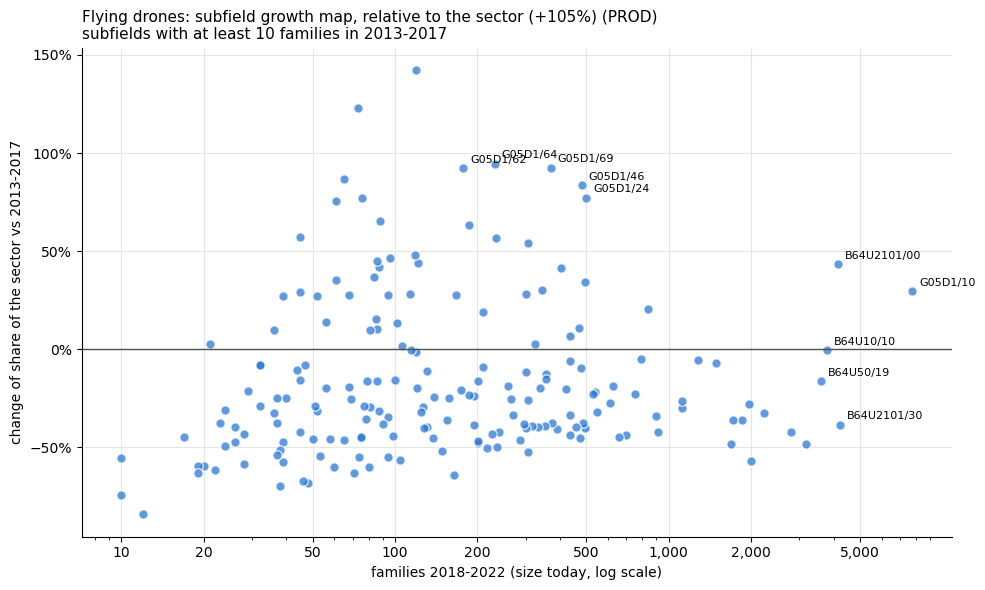

187 subfields shown out of 214


In [19]:
from matplotlib.ticker import FuncFormatter, NullFormatter

MIN_SUBFIELD_FAMILIES = 10   # growth from fewer families in the past period is not meaningful

plot = subfields[subfields[past_col] >= MIN_SUBFIELD_FAMILIES]
size_today = plot[recent_col]
fastest = plot[size_today >= size_today.median()].sort_values("growth vs sector (%)", ascending=False).head(5)
to_label = set(fastest.index) | set(plot.head(5).index)   # label the 5 fastest-growing and the 5 largest

x = plot[recent_col].clip(lower=1)                        # a subfield with 0 families today is drawn at 1
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, plot["growth vs sector (%)"], s=45, color=C_MAIN, alpha=0.75, edgecolor="white", linewidth=1)
for name in to_label:
    ax.annotate(name, (x[name], plot.loc[name, "growth vs sector (%)"]),
                xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color=C_MUTED, lw=1)                       # above the line: growing faster than the sector

ax.set_xscale("log")
ticks = [t for t in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000) if x.min() * 0.7 <= t <= x.max() * 1.4]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today, log scale)",
       ylabel=f"change of share of the sector vs {PAST[0]}-{PAST[1]}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_title(f"{SECTOR_NAME}: subfield growth map, relative to the sector ({sector_growth:+.0f}%) ({ENV})\n"
             f"subfields with at least {MIN_SUBFIELD_FAMILIES} families in {PAST[0]}-{PAST[1]}",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "fig_step2_subfield_growth_map.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"{len(plot)} subfields shown out of {len(subfields)}")